# GTX-A 126개 격자의 실제 수요 변화
2024-10-17 / 2025-11-06 합성 승차자료. 전체 126개 유지. 머신러닝·이진분류·40명 기준을 사용하지 않는다.
권역 전체는 최근접 GTX역에 배정된 분석격자 집합이며 행정구역 전체 수요가 아니다.
별도 CSV·그림·모델 파일은 저장하지 않고 표와 그림을 이 노트북에 표시한다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
HERE = next((UROP_ROOT / 'code').rglob('12-2_Ridge_Logistic_예측성능_개선실험.py')).parent
spec=importlib.util.spec_from_file_location('eda32_source',next((UROP_ROOT / 'code').rglob('12-2_Ridge_Logistic_예측성능_개선실험.py')))
base=importlib.util.module_from_spec(spec);spec.loader.exec_module(base)
data=base.load_data()
assert len(data)==126 and data['셀 ID'].is_unique
for font in ['/System/Library/Fonts/AppleSDGothicNeo.ttc','/Library/Fonts/NanumGothic.ttf']:
    if Path(font).exists():
        fm.fontManager.addfont(font);plt.rcParams['font.family']=fm.FontProperties(fname=font).get_name();break
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['figure.dpi']=120
order=['운정중앙','킨텍스','대곡']
colors={'운정중앙':'#2878B5','킨텍스':'#E07B39','대곡':'#4A9651'}
df=data[['셀 ID','nearest_station','board_2024_all','board_2025_all']].rename(columns={'nearest_station':'권역','board_2024_all':'2024년 승차인원','board_2025_all':'2025년 승차인원'}).copy()
assert df[['2024년 승차인원','2025년 승차인원']].notna().all().all()
df['절대 변화량(명)']=df['2025년 승차인원']-df['2024년 승차인원']
zero=df['2024년 승차인원'].eq(0)
df['격자 변화율(%)']=np.where(~zero,df['절대 변화량(명)']/df['2024년 승차인원']*100,np.nan)
station=df.groupby('권역')[['2024년 승차인원','2025년 승차인원']].sum().reindex(order)
station['격자 수']=df.groupby('권역').size()
station['절대 변화량(명)']=station['2025년 승차인원']-station['2024년 승차인원']
station['권역 전체 변화율(%)']=station['절대 변화량(명)']/station['2024년 승차인원']*100
df['권역 전체 변화율(%)']=df['권역'].map(station['권역 전체 변화율(%)'])
df['권역 대비 차이(%p)']=df['격자 변화율(%)']-df['권역 전체 변화율(%)']
assert df['격자 변화율(%)'].notna().sum()+zero.sum()==126
print('개통 전 0명:',int(zero.sum()),'개 (해당 시 변화율만 결측으로 유지, 격자는 제외하지 않음)')
print('감소/동일/증가:',int((df['절대 변화량(명)']<0).sum()),int((df['절대 변화량(명)']==0).sum()),int((df['절대 변화량(명)']>0).sum()))
display(station.round(3))
display(df[['격자 변화율(%)','권역 대비 차이(%p)','2024년 승차인원','절대 변화량(명)']].describe(percentiles=[.1,.25,.5,.75,.9,.95]).round(3))
print('전체 수요 가중 변화율:',round((df['2025년 승차인원'].sum()/df['2024년 승차인원'].sum()-1)*100,3),'%')

개통 전 0명: 0 개 (해당 시 변화율만 결측으로 유지, 격자는 제외하지 않음)
감소/동일/증가: 117 5 4
전체 수요 가중 변화율: -68.788 %


,2024년 승차인원,2025년 승차인원,격자 수,절대 변화량(명),권역 전체 변화율(%)
권역,,,,,
운정중앙,6491.0,1911.0,63,-4580.0,-70.559
킨텍스,8781.0,2658.0,26,-6123.0,-69.730
대곡,2622.0,1016.0,37,-1606.0,-61.251


,격자 변화율(%),권역 대비 차이(%p),2024년 승차인원,절대 변화량(명)
count,126.000,126.000,126.000,126.000
mean,-57.171,10.484,142.016,-97.690
std,42.357,42.095,271.880,190.908
min,-93.750,-32.499,1.000,-1382.000
10%,-81.612,-13.029,4.000,-210.000
25%,-74.350,-6.564,13.000,-87.500
50%,-66.667,0.588,63.500,-39.500
75%,-52.632,11.251,122.750,-8.000
90%,-28.856,37.764,293.500,-2.000
95%,0.000,68.232,613.000,0.000


## 전체 126개 계산표
행을 제외하지 않으며 셀 ID로 기존 분석과 대조할 수 있다. 변화량은 2025−2024로 감소가 음수다.

In [2]:
with pd.option_context('display.max_rows',126,'display.max_columns',10):
    display(df.sort_values(['권역','셀 ID']).round(3).reset_index(drop=True))

,셀 ID,권역,2024년 승차인원,2025년 승차인원,절대 변화량(명),격자 변화율(%),권역 전체 변화율(%),권역 대비 차이(%p)
0,44,대곡,269.0,91.0,-178.0,-66.171,-61.251,-4.920
1,1235,대곡,6.0,1.0,-5.0,-83.333,-61.251,-22.082
2,1518,대곡,3.0,1.0,-2.0,-66.667,-61.251,-5.416
3,1712,대곡,43.0,16.0,-27.0,-62.791,-61.251,-1.540
4,1713,대곡,111.0,46.0,-65.0,-58.559,-61.251,2.692
5,1962,대곡,4.0,4.0,0.0,0.000,-61.251,61.251
6,2477,대곡,130.0,34.0,-96.0,-73.846,-61.251,-12.595
7,2716,대곡,73.0,29.0,-44.0,-60.274,-61.251,0.977
8,2718,대곡,99.0,26.0,-73.0,-73.737,-61.251,-12.486
9,3424,대곡,64.0,24.0,-40.0,-62.500,-61.251,-1.249


## 변화율 분포
극단값을 삭제하거나 윈저화하지 않는다. 히스토그램은 전체 범위, 상자그림은 모든 격자의 점을 표시한다.

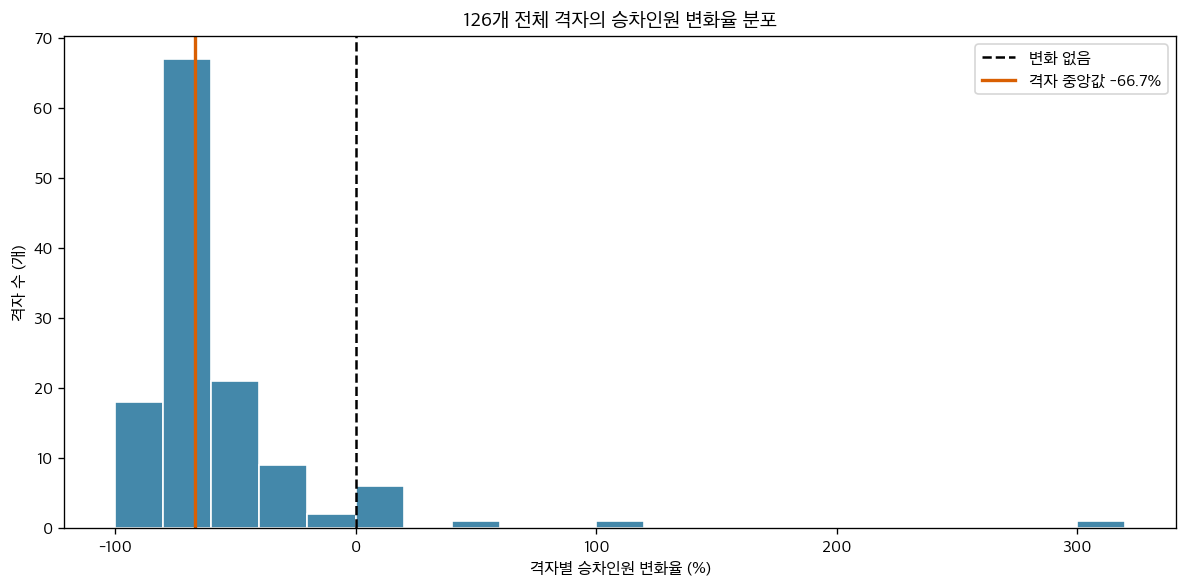

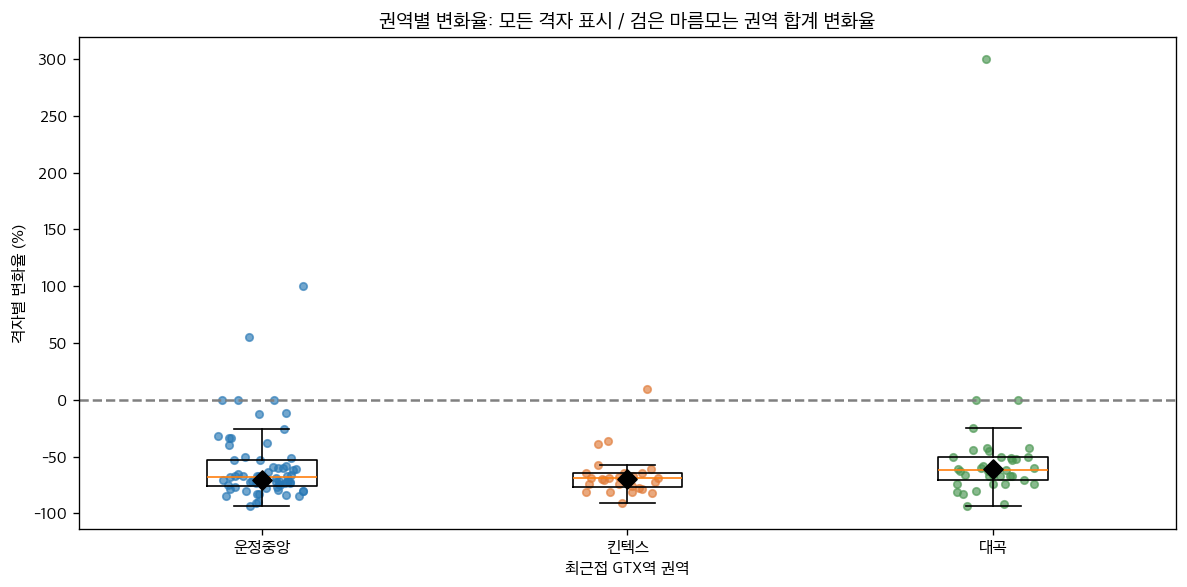

In [3]:
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(df['격자 변화율(%)'].dropna(),bins=np.arange(-100,321,20),color='#4488AA',edgecolor='white')
ax.axvline(0,color='black',ls='--',label='변화 없음')
ax.axvline(df['격자 변화율(%)'].median(),color='#D95F02',lw=2,label=f"격자 중앙값 {df['격자 변화율(%)'].median():.1f}%")
ax.set(xlabel='격자별 승차인원 변화율 (%)',ylabel='격자 수 (개)',title='126개 전체 격자의 승차인원 변화율 분포')
ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,5))
ax.boxplot([df.loc[df.권역==s,'격자 변화율(%)'].dropna() for s in order],tick_labels=order,showfliers=False)
rng=np.random.default_rng(42)
for i,s in enumerate(order,1):
    part=df[df.권역==s]
    ax.scatter(i+rng.uniform(-.12,.12,len(part)),part['격자 변화율(%)'],s=20,color=colors[s],alpha=.65)
    ax.scatter(i,station.loc[s,'권역 전체 변화율(%)'],marker='D',s=65,color='black',zorder=5)
ax.axhline(0,color='gray',ls='--');ax.set(ylabel='격자별 변화율 (%)',xlabel='최근접 GTX역 권역',title='권역별 변화율: 모든 격자 표시 / 검은 마름모는 권역 합계 변화율')
plt.tight_layout();plt.show()

## 개통 전 승차규모와 변화율
왼쪽은 원 단위 x축, 오른쪽은 같은 자료의 로그 눈금 x축이다. 승차인원 값을 변환해 모형을 학습하는 것이 아니다.

Spearman 순위상관(기술적 요약, 공간 독립성 가정의 p값은 제시하지 않음): -0.371


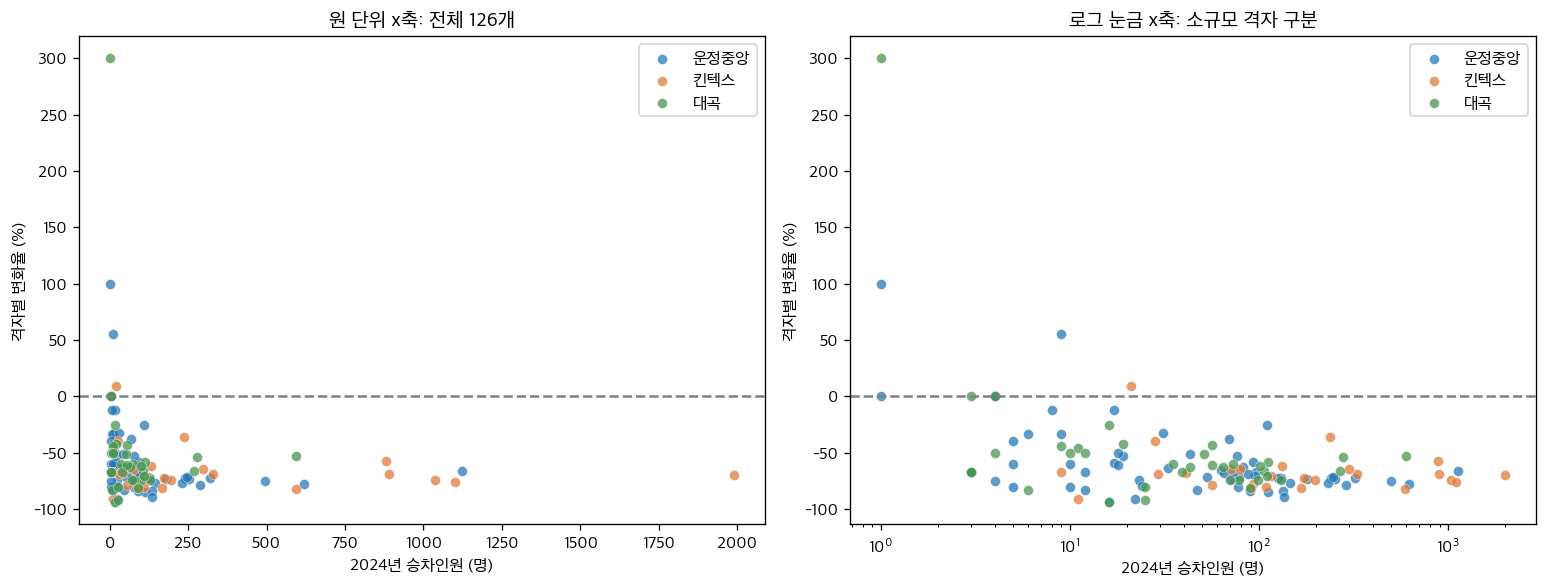

,격자수,개통전합계,개통후합계,변화율중앙값,최소변화율,최대변화율,합계기준변화율(%)
개통 전 규모,,,,,,,
0~4명,14,41.0,30.0,-25.000,-75.000,300.000,-26.829
5~9명,10,71.0,46.0,-42.222,-83.333,55.556,-35.211
10~19명,17,244.0,102.0,-58.824,-93.750,-11.765,-58.197
20~39명,12,335.0,129.0,-67.816,-92.000,9.524,-61.493
40~99명,33,2367.0,762.0,-67.692,-84.270,-37.681,-67.807
100명 이상,40,14836.0,4516.0,-72.404,-89.630,-25.455,-69.561


In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax in axes:
    for s in order:
        p=df[df.권역==s];ax.scatter(p['2024년 승차인원'],p['격자 변화율(%)'],label=s,color=colors[s],alpha=.75,edgecolor='white',linewidth=.3)
    ax.axhline(0,color='gray',ls='--');ax.set(xlabel='2024년 승차인원 (명)',ylabel='격자별 변화율 (%)');ax.legend()
axes[0].set_title('원 단위 x축: 전체 126개')
axes[1].set_xscale('log');axes[1].set_title('로그 눈금 x축: 소규모 격자 구분')
plt.tight_layout();plt.show()
print('Spearman 순위상관(기술적 요약, 공간 독립성 가정의 p값은 제시하지 않음):',round(df['2024년 승차인원'].corr(df['격자 변화율(%)'],method='spearman'),3))
df['개통 전 규모']=pd.cut(df['2024년 승차인원'],[0,5,10,20,40,100,np.inf],right=False,labels=['0~4명','5~9명','10~19명','20~39명','40~99명','100명 이상'])
scale=df.groupby('개통 전 규모',observed=True).agg(격자수=('셀 ID','size'),개통전합계=('2024년 승차인원','sum'),개통후합계=('2025년 승차인원','sum'),변화율중앙값=('격자 변화율(%)','median'),최소변화율=('격자 변화율(%)','min'),최대변화율=('격자 변화율(%)','max'))
scale['합계기준변화율(%)']=(scale.개통후합계/scale.개통전합계-1)*100
display(scale.round(3))

## 소규모 격자와 극단값
규모 구간은 진단용이며 표본 제외 기준이 아니다. 아래는 변화율 최댓값·최솟값 각 10개와 개통 전 10명 미만 전체를 표시한다.

In [5]:
cols=['셀 ID','권역','2024년 승차인원','2025년 승차인원','절대 변화량(명)','격자 변화율(%)','권역 전체 변화율(%)','권역 대비 차이(%p)']
print('변화율 상위10');display(df.nlargest(10,'격자 변화율(%)')[cols].round(3))
print('변화율 하위10');display(df.nsmallest(10,'격자 변화율(%)')[cols].round(3))
print('개통 전10명 미만 전체');display(df[df['2024년 승차인원']<10][cols].sort_values('격자 변화율(%)',ascending=False).round(3))

변화율 상위10
변화율 하위10
개통 전10명 미만 전체


,셀 ID,권역,2024년 승차인원,2025년 승차인원,절대 변화량(명),격자 변화율(%),권역 전체 변화율(%),권역 대비 차이(%p)
115,14004,대곡,1.0,4.0,3.0,300.000,-61.251,361.251
47,7262,운정중앙,1.0,2.0,1.0,100.000,-70.559,170.559
46,6952,운정중앙,9.0,14.0,5.0,55.556,-70.559,126.115
116,14062,킨텍스,21.0,23.0,2.0,9.524,-69.730,79.254
16,1962,대곡,4.0,4.0,0.0,0.000,-61.251,61.251
29,4012,운정중앙,4.0,4.0,0.0,0.000,-70.559,70.559
34,4768,운정중앙,1.0,1.0,0.0,0.000,-70.559,70.559
48,7368,대곡,3.0,3.0,0.0,0.000,-61.251,61.251
57,8635,운정중앙,4.0,4.0,0.0,0.000,-70.559,70.559
1,76,운정중앙,17.0,15.0,-2.0,-11.765,-70.559,58.795


,셀 ID,권역,2024년 승차인원,2025년 승차인원,절대 변화량(명),격자 변화율(%),권역 전체 변화율(%),권역 대비 차이(%p)
24,3056,운정중앙,16.0,1.0,-15.0,-93.750,-70.559,-23.191
77,10471,대곡,16.0,1.0,-15.0,-93.750,-61.251,-32.499
104,12984,대곡,25.0,2.0,-23.0,-92.000,-61.251,-30.749
31,4205,킨텍스,11.0,1.0,-10.0,-90.909,-69.730,-21.179
79,10574,운정중앙,22.0,2.0,-20.0,-90.909,-70.559,-20.350
111,13602,운정중앙,135.0,14.0,-121.0,-89.630,-70.559,-19.070
5,1115,운정중앙,111.0,17.0,-94.0,-84.685,-70.559,-14.125
28,3765,운정중앙,89.0,14.0,-75.0,-84.270,-70.559,-13.710
110,13318,운정중앙,134.0,22.0,-112.0,-83.582,-70.559,-13.023
8,1235,대곡,6.0,1.0,-5.0,-83.333,-61.251,-22.082


,셀 ID,권역,2024년 승차인원,2025년 승차인원,절대 변화량(명),격자 변화율(%),권역 전체 변화율(%),권역 대비 차이(%p)
115,14004,대곡,1.0,4.0,3.0,300.000,-61.251,361.251
47,7262,운정중앙,1.0,2.0,1.0,100.000,-70.559,170.559
46,6952,운정중앙,9.0,14.0,5.0,55.556,-70.559,126.115
57,8635,운정중앙,4.0,4.0,0.0,0.000,-70.559,70.559
16,1962,대곡,4.0,4.0,0.0,0.000,-61.251,61.251
48,7368,대곡,3.0,3.0,0.0,0.000,-61.251,61.251
29,4012,운정중앙,4.0,4.0,0.0,0.000,-70.559,70.559
34,4768,운정중앙,1.0,1.0,0.0,0.000,-70.559,70.559
54,7883,운정중앙,8.0,7.0,-1.0,-12.500,-70.559,58.059
19,2295,운정중앙,6.0,4.0,-2.0,-33.333,-70.559,37.226


## 역 권역별 변화율 지도
원래 011 확대지도와 같은 로컬 격자 방식. 온라인 지도·API 호출 없음. 126개 공통 사분위 범례, 0% 이상 격자는 파란 외곽선. 색은 절대 변화량이 아닌 변화율이다. 배경은 분석지역 행정경계이며 도로 배경지도는 아니다.

운정중앙 격자 변화율 범위: -93.75 ~ 100.0 %
킨텍스 격자 변화율 범위: -90.91 ~ 9.52 %
대곡 격자 변화율 범위: -93.75 ~ 300.0 %


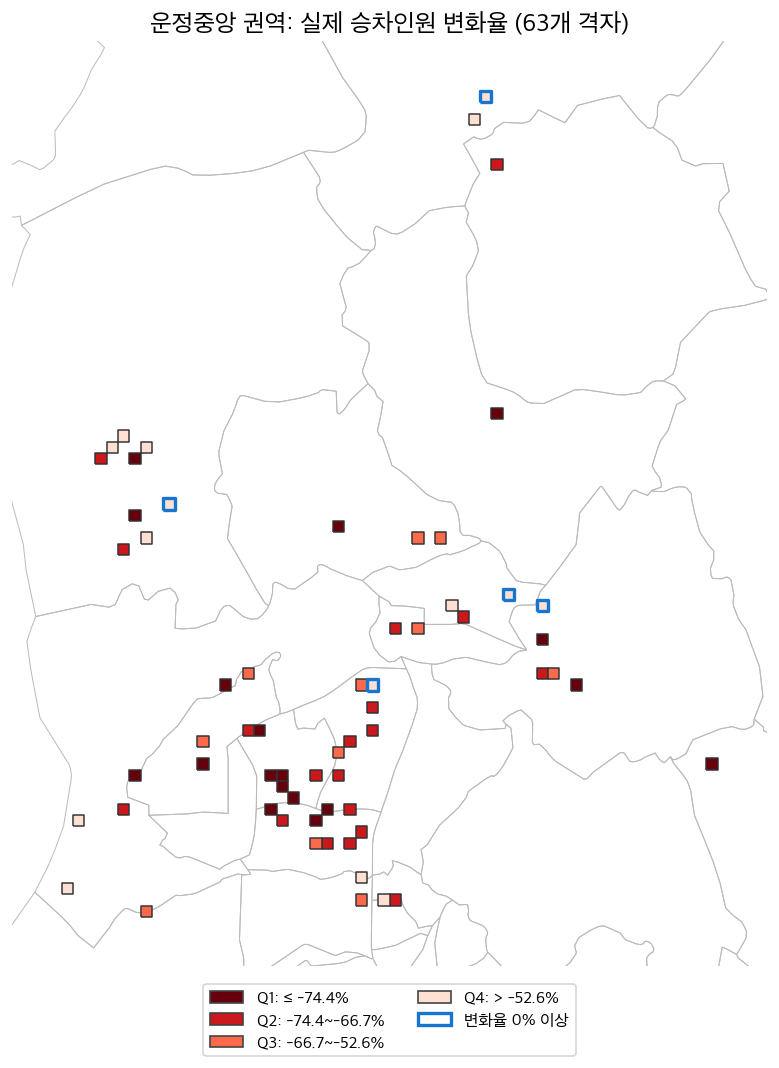

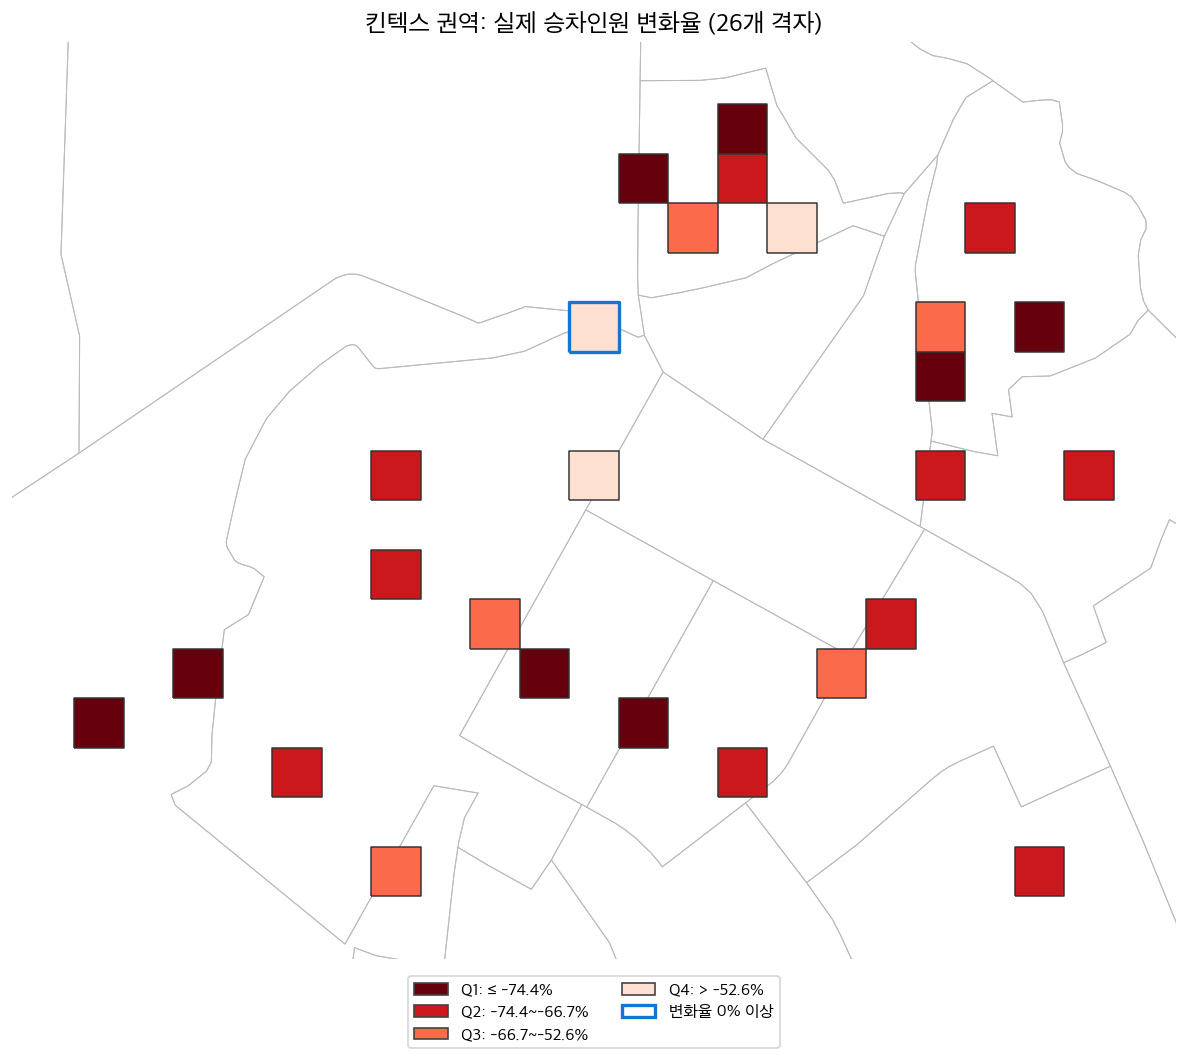

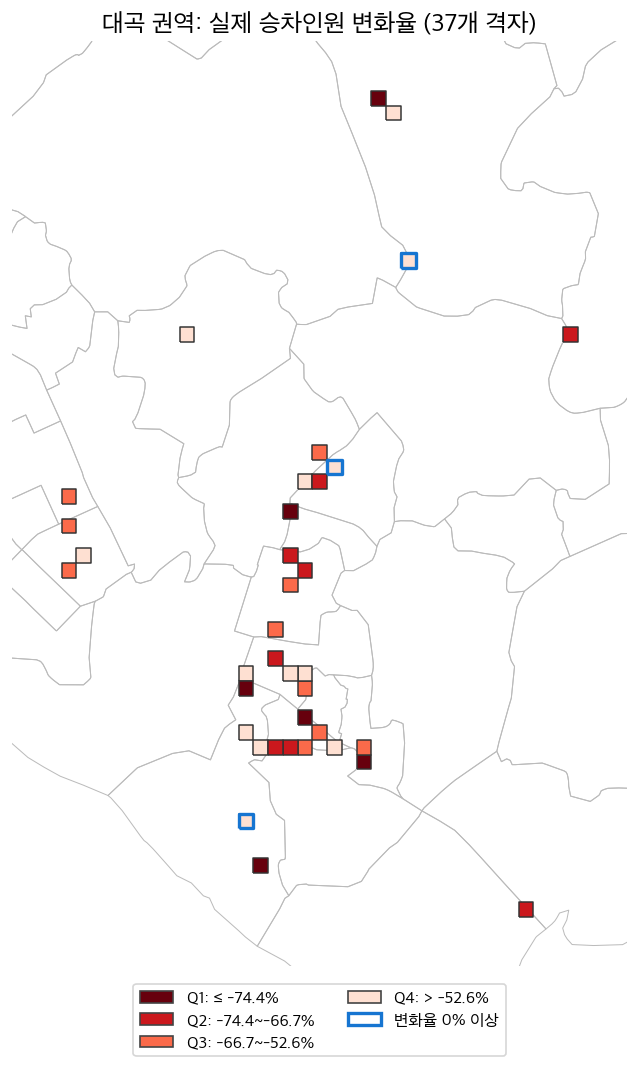

,사분위,격자수,범례
0,Q1,32,Q1: ≤ -74.4%
1,Q2,37,Q2: -74.4~-66.7%
2,Q3,26,Q3: -66.7~-52.6%
3,Q4,31,Q4: > -52.6%


In [6]:
import geopandas as gpd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
ROOT=UROP_ROOT
PROJECT=UROP_ROOT
GRID_PATH=next((ROOT/'data' / 'raw' / 'common' / 'grid' / '빈격자(250m)').glob('*.shp'))
ADMIN_PATH=ROOT/'data' / 'raw' / 'common' / 'api_cache_gtx_a_routes'/'HangJeongDong_ver20260701.geojson'
crs=gpd.read_file(GRID_PATH,rows=1).crs
admin=gpd.read_file(ADMIN_PATH).to_crs(crs)
admin['sgg_code']=admin['sgg'].astype(str).str.extract(r'([0-9]+)')[0].str.zfill(5)
city=admin[admin.sgg_code.str.startswith(('4128','4148'))]
boundary=city.geometry.union_all() if hasattr(city.geometry,'union_all') else city.geometry.unary_union
grid=gpd.read_file(GRID_PATH,bbox=boundary.bounds)
grid=grid[grid.geometry.intersects(boundary)].copy()
grid['_key']=grid.geometry.apply(lambda g:g.wkb)
grid=grid.drop_duplicates('_key').drop(columns='_key').reset_index(drop=True)
grid['셀 ID']=np.arange(1,len(grid)+1)
geo=grid[['셀 ID','geometry']].merge(df,on='셀 ID',how='inner',validate='one_to_one')
assert len(geo)==126
q=df['격자 변화율(%)'].quantile([.25,.5,.75]).to_numpy()
geo['구간']=pd.cut(geo['격자 변화율(%)'],[-np.inf,*q,np.inf],labels=False,include_lowest=True)
palette=['#67000D','#CB181D','#FB6A4A','#FEE0D2']
labels=[f'Q1: ≤ {q[0]:.1f}%',f'Q2: {q[0]:.1f}~{q[1]:.1f}%',f'Q3: {q[1]:.1f}~{q[2]:.1f}%',f'Q4: > {q[2]:.1f}%']
handles=[Patch(facecolor=c,edgecolor='#444444',label=l) for c,l in zip(palette,labels)]
handles.append(Patch(facecolor='none',edgecolor='#1675D1',linewidth=2,label='변화율 0% 이상'))
for s in order:
    part=geo[geo.권역==s];x0,y0,x1,y1=part.total_bounds
    pad=max((x1-x0)*.06,(y1-y0)*.06,250)
    fig,ax=plt.subplots(figsize=(10,9))
    city.boundary.plot(ax=ax,color='#BBBBBB',linewidth=.6,zorder=0)
    part.plot(ax=ax,column='구간',cmap=ListedColormap(palette),vmin=-.5,vmax=3.5,edgecolor='#333333',linewidth=.9,zorder=2)
    nonnegative=part[part['격자 변화율(%)']>=0]
    if len(nonnegative):nonnegative.boundary.plot(ax=ax,color='#1675D1',linewidth=2,zorder=3)
    ax.set_xlim(x0-pad,x1+pad);ax.set_ylim(y0-pad,y1+pad);ax.set_aspect('equal');ax.axis('off')
    ax.set_title(f'{s} 권역: 실제 승차인원 변화율 ({len(part)}개 격자)',fontsize=15)
    ax.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,-.01),ncol=2,fontsize=10)
    plt.tight_layout();plt.show()
    print(s,'격자 변화율 범위:',round(part['격자 변화율(%)'].min(),2),'~',round(part['격자 변화율(%)'].max(),2),'%')
display(pd.DataFrame({'사분위':['Q1','Q2','Q3','Q4'],'격자수':geo['구간'].value_counts().reindex(range(4),fill_value=0).to_numpy(),'범례':labels}))

## 해석 시 주의
- 격자 변화율의 단순평균과 전체 승차인원 합계의 변화율은 다르다. 후자는 개통 전 승차인원으로 가중한 변화율이다.
- +300% 같은 값은 작은 분모에서 발생할 수 있어 전후 승차인원과 절대 변화량을 함께 확인한다.
- 권역 대비 차이가 양수여도 절대 승차인원이 증가했다는 뜻은 아니다.
- 두 날짜 합성자료의 비교이며 GTX의 인과효과로 단정하지 않는다.
- 지도는 동일한 전체126개 공통 사분위이며 Q4에도 감소격자가 포함된다. 극단값을 삭제하지 않는다.